# 02 · Modelling & validation

How the forecasts are produced and how good they are, measured honestly:

1. build leakage-free features (`football_predictor.features`);
2. walk-forward validation by season, against simple baselines and the bookmakers;
3. choose the blend between the classifier and the Poisson goals model;
4. calibration, feature importance and the score model;
5. export the validation table to the website (`web/public/data/evaluation.json`).

**Metrics.** *Accuracy* = share of matches where the most likely outcome happened. *Log loss* and *Brier* score the
probabilities themselves. *RPS* (ranked probability score) is the standard in football forecasting because it
knows that predicting a draw when the home side wins is "less wrong" than predicting an away win. Lower is better
for the last three.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

# Colours shared with the website (validated for colour-vision deficiency)
HOME, DRAW, AWAY = "#2a78d6", "#1baf7a", "#eb6834"
GRID, INK, MUTED = "#e2e0da", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})

In [2]:
import json
from datetime import datetime, timezone

from football_predictor import evaluation as ev
from football_predictor.config import WEB_DATA_DIR
from football_predictor.dataset import build_matches
from football_predictor.features import build_features, feature_columns
from football_predictor.model import MatchModel, training_rows

matches = build_matches(refresh=False, save=False)
frame, _ = build_features(matches)
rows = training_rows(frame)
FEATURES = feature_columns(frame)
print(f"{len(rows):,} training rows · {len(FEATURES)} features")

89,875 training rows · 62 features


## 1. Features

Every feature of a match uses only information available before kick-off. `tests/test_features.py` checks this by
changing a match's score and asserting that none of that match's features move.

In [3]:
pd.Series(FEATURES).to_frame("feature").T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,...,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61
feature,home_elo,away_elo,elo_diff,elo_p_home,mkt_p_home,mkt_p_draw,mkt_p_away,is_cup,is_uefa,tier,neutral,comp_avg_goals,comp_home_win_rate,comp_draw_rate,home_rest,...,home_ga_10,home_ga_5,home_ga_venue5,home_gf_10,home_gf_5,home_gf_venue5,home_points_10,home_points_5,home_points_venue5,home_shots_against_5,home_shots_for_5,home_sot_against_5,home_sot_for_5,home_xg_against_5,home_xg_for_5


In [4]:
rows[["date", "competition", "home_team", "away_team", "home_elo", "away_elo", "elo_p_home",
      "home_points_5", "away_points_5", "home_pos", "away_pos", "mkt_p_home", "result"]].tail(5)

,date,competition,home_team,away_team,home_elo,away_elo,elo_p_home,home_points_5,away_points_5,home_pos,away_pos,mkt_p_home,result
99911,2026-11-23,SWE,Hammarby,Goteborg,1682.733972,1505.570923,0.801230,3.0,0.8,0.066667,0.600000,0.816814,H
99912,2026-11-23,SWE,Orgryte,Kalmar,1366.536984,1377.991511,0.576454,1.0,1.4,1.000000,0.800000,0.278471,H
99913,2026-11-23,T1,Buyuksehyr,Corum,1608.740256,1498.995093,0.732220,2.0,1.8,0.470588,0.588235,0.495512,H
99914,2026-11-24,CL,Bodo/Glimt,LASK,1783.024613,1637.935799,0.770187,2.0,2.4,NaN,NaN,NaN,H
99915,2026-11-24,CL,Galatasaray,Aston Villa,1805.824159,1844.783509,0.537405,3.0,0.6,NaN,NaN,NaN,H


## 2. Walk-forward validation

For each of the last three complete seasons, train only on earlier seasons and predict the whole season. This is
how the model is used in production (it never sees the future), so the numbers are honest out-of-sample estimates.

In [5]:
from sklearn.linear_model import LogisticRegression

TEST_SEASONS = [2023, 2024, 2025]
collected = []
for season in TEST_SEASONS:
    train = rows[rows["season"] < season]
    test = rows[rows["season"] == season]
    model = MatchModel().fit(train, FEATURES)
    pred = model.predict(test)

    # Baseline: logistic regression on the Elo difference only
    elo_lr = LogisticRegression(max_iter=1000).fit(train[["elo_diff"]], train["target"].astype(int))
    elo_p = elo_lr.predict_proba(test[["elo_diff"]])

    out = test[["season", "competition", "target", "home_goals", "away_goals", "mkt_p_home", "mkt_p_draw", "mkt_p_away"]].copy()
    out[["blend_h", "blend_d", "blend_a"]] = pred[["p_home", "p_draw", "p_away"]].to_numpy()
    out[["cls_h", "cls_d", "cls_a"]] = pred[["cls_p_home", "cls_p_draw", "cls_p_away"]].to_numpy()
    out[["pois_h", "pois_d", "pois_a"]] = pred[["pois_p_home", "pois_p_draw", "pois_p_away"]].to_numpy()
    out[["elo_h", "elo_d", "elo_a"]] = elo_p
    out[["base_h", "base_d", "base_a"]] = ev.baseline_frequencies(train["target"].to_numpy(), len(test))
    out[["xg_home", "xg_away"]] = pred[["xg_home", "xg_away"]].to_numpy()
    collected.append(out)
    print(f"season {season}/{season + 1}: trained on {len(train):,}, tested on {len(test):,}")

oos = pd.concat(collected)
y = oos["target"].astype(int).to_numpy()

season 2023/2024: trained on 63,253, tested on 7,798


season 2024/2025: trained on 71,051, tested on 7,764


season 2025/2026: trained on 78,815, tested on 7,739


In [6]:
CANDIDATES = {
    "Historical frequencies": ["base_h", "base_d", "base_a"],
    "Elo only (logistic)": ["elo_h", "elo_d", "elo_a"],
    "Poisson goals model": ["pois_h", "pois_d", "pois_a"],
    "XGBoost classifier": ["cls_h", "cls_d", "cls_a"],
    "Final model (blend)": ["blend_h", "blend_d", "blend_a"],
}
table = pd.DataFrame({name: ev.summarise(oos[cols].to_numpy(), y) for name, cols in CANDIDATES.items()}).T
table.style.format({"n": "{:,.0f}", "accuracy": "{:.1%}", "log_loss": "{:.4f}", "brier": "{:.4f}", "rps": "{:.4f}"})

,n,accuracy,log_loss,brier,rps
Historical frequencies,"23,301",44.4%,1.0658,0.6448,0.2325
Elo only (logistic),"23,301",51.9%,0.9898,0.5898,0.2059
Poisson goals model,"23,301",53.4%,0.9713,0.5770,0.2005
XGBoost classifier,"23,301",53.4%,0.9551,0.5717,0.1994
Final model (blend),"23,301",53.4%,0.9551,0.5717,0.1994


On every metric the model beats the naive baselines by a wide margin and improves on a pure Elo model. The real
test is the bookmakers, compared on the matches where odds exist:

In [7]:
has_odds = oos[["mkt_p_home", "mkt_p_draw", "mkt_p_away"]].notna().all(axis=1).to_numpy()
vs_market = pd.DataFrame({
    "Bookmakers (margin removed)": ev.summarise(oos.loc[has_odds, ["mkt_p_home", "mkt_p_draw", "mkt_p_away"]].to_numpy(), y[has_odds]),
    "Final model (blend)": ev.summarise(oos.loc[has_odds, ["blend_h", "blend_d", "blend_a"]].to_numpy(), y[has_odds]),
}).T
vs_market.style.format({"n": "{:,.0f}", "accuracy": "{:.1%}", "log_loss": "{:.4f}", "brier": "{:.4f}", "rps": "{:.4f}"})

,n,accuracy,log_loss,brier,rps
Bookmakers (margin removed),"19,826",51.6%,0.9893,0.5903,0.2003
Final model (blend),"19,826",51.4%,0.9902,0.5910,0.2005


The model essentially matches the market. That is the expected ceiling for public data: the market price is one of
the model's inputs and already contains information (injuries, line-ups, news) that the model has no access to.

European matches are the opposite case: there are no historical odds for them, so the model relies on ratings and form
alone (the old version could not predict them at all):

In [8]:
cups = oos["competition"].isin(["CL", "EL", "ECL"]).to_numpy()
pd.DataFrame({
    "UEFA competitions": ev.summarise(oos.loc[cups, ["blend_h", "blend_d", "blend_a"]].to_numpy(), y[cups]),
    "Domestic leagues": ev.summarise(oos.loc[~cups, ["blend_h", "blend_d", "blend_a"]].to_numpy(), y[~cups]),
}).T.style.format({"n": "{:,.0f}", "accuracy": "{:.1%}", "log_loss": "{:.4f}", "brier": "{:.4f}", "rps": "{:.4f}"})

,n,accuracy,log_loss,brier,rps
UEFA competitions,"1,429",55.8%,0.9547,0.5657,0.2052
Domestic leagues,"21,872",53.3%,0.9551,0.5721,0.1991


Accuracy is higher in UEFA games because they contain more mismatches between clubs of very different
strength, while the RPS is slightly worse than in domestic leagues: that gap is the value of the missing market
information.

## 3. Choosing the blend weight

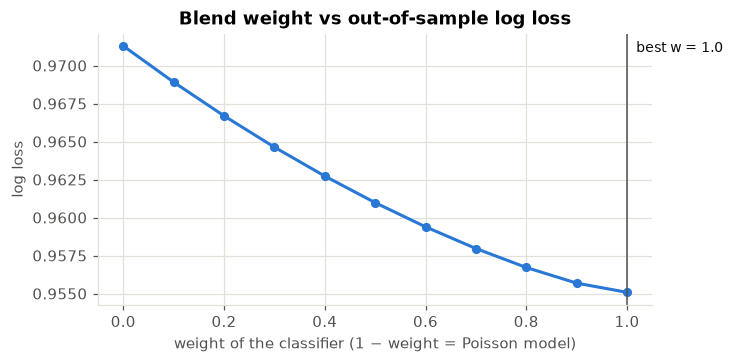

w,0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0
log_loss,0.9713,0.9689,0.9667,0.9646,0.9627,0.9610,0.9594,0.9580,0.9567,0.9557,0.9551
rps,0.2005,0.2002,0.2000,0.1998,0.1997,0.1996,0.1995,0.1994,0.1994,0.1994,0.1994
accuracy,0.5344,0.5339,0.5343,0.5340,0.5347,0.5344,0.5345,0.5345,0.5343,0.5343,0.5342


In [9]:
weights = np.linspace(0, 1, 11)
cls = oos[["cls_h", "cls_d", "cls_a"]].to_numpy()
poi = oos[["pois_h", "pois_d", "pois_a"]].to_numpy()
sweep = pd.DataFrame([{"w": w, **ev.summarise(w * cls + (1 - w) * poi, y)} for w in weights]).set_index("w")

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(sweep.index, sweep["log_loss"], color=HOME, lw=2, marker="o", ms=5)
best = sweep["log_loss"].idxmin()
ax.axvline(best, color=MUTED, lw=1)
ax.annotate(f"best w = {best:.1f}", (best, sweep["log_loss"].max()), xytext=(6, -4), textcoords="offset points", color=INK, fontsize=9)
ax.set_xlabel("weight of the classifier (1 − weight = Poisson model)")
ax.set_ylabel("log loss")
ax.set_title("Blend weight vs out-of-sample log loss")
plt.show()
sweep[["log_loss", "rps", "accuracy"]].round(4).T

Log loss keeps falling up to a weight of 1, with RPS and accuracy flat: once the domestic cups are included the
classifier alone is the best 1X2 model (a 70/30 blend was marginally better on leagues only). Production therefore uses
`BLEND_WEIGHT = 1.0`; the Poisson models still provide expected goals and the correct-score grid.

## 4. Calibration

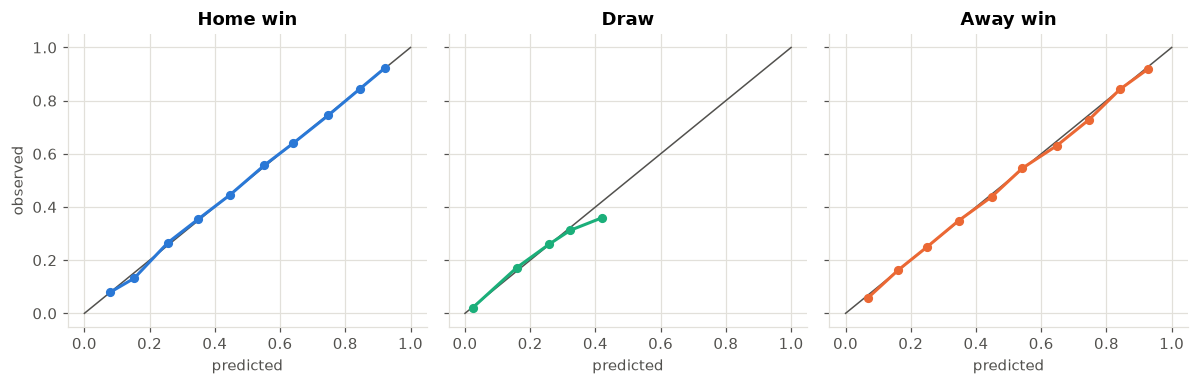

In [10]:
probs = oos[["blend_h", "blend_d", "blend_a"]].to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6), sharey=True)
for i, (ax, label, color) in enumerate(zip(axes, ["Home win", "Draw", "Away win"], [HOME, DRAW, AWAY])):
    p = probs[:, i]
    o = (y == i).astype(float)
    b = pd.cut(p, np.linspace(0, 1, 11))
    c = pd.DataFrame({"p": p, "o": o}).groupby(b, observed=True).agg(p=("p", "mean"), o=("o", "mean"), n=("o", "size"))
    c = c[c["n"] >= 30]
    ax.plot([0, 1], [0, 1], color=MUTED, lw=1)
    ax.plot(c["p"], c["o"], color=color, lw=2, marker="o", ms=5)
    ax.set_title(label)
    ax.set_xlabel("predicted")
axes[0].set_ylabel("observed")
plt.tight_layout()
plt.show()

All three outcomes stay close to the diagonal: when the model says 60%, it happens about 60% of the time. Draw
probabilities live in a narrow band (roughly 16–32% for nine matches in ten), which is why a draw is almost never the
single most likely outcome.

## 5. What drives the predictions

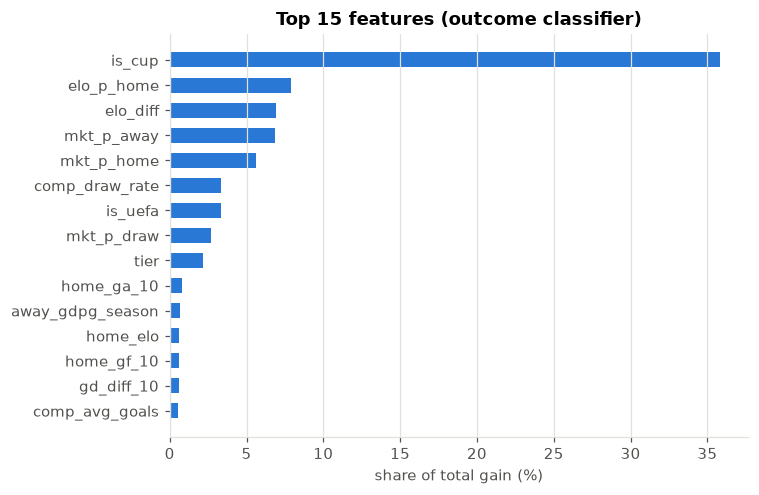

In [11]:
final = MatchModel().fit(rows, FEATURES)
importance = final.feature_importance().head(15)

fig, ax = plt.subplots(figsize=(7, 4.6))
ax.barh(importance.index[::-1], importance.values[::-1] * 100, color=HOME, height=0.6)
ax.set_xlabel("share of total gain (%)")
ax.set_title("Top 15 features (outcome classifier)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

Market probabilities and Elo carry most of the signal; form, league position and competition context refine it.
The old model's list contained duplicated and unused features (motivation constants, fixed market values of 200/900
for unknown clubs) that are gone now.

## 6. Goals and correct scores

In [12]:
mae_home = np.mean(np.abs(oos["xg_home"] - oos["home_goals"]))
mae_away = np.mean(np.abs(oos["xg_away"] - oos["away_goals"]))
naive = np.mean(np.abs(rows.loc[rows["season"] < 2023, "home_goals"].mean() - oos["home_goals"]))
pred_score = np.floor(oos["xg_home"]).astype(int).astype(str) + "-" + np.floor(oos["xg_away"]).astype(int).astype(str)
real_score = oos["home_goals"].astype(int).astype(str) + "-" + oos["away_goals"].astype(int).astype(str)
print(f"Mean absolute error, home goals: {mae_home:.3f} (constant-average baseline {naive:.3f})")
print(f"Mean absolute error, away goals: {mae_away:.3f}")
print(f"Most-likely score was exactly right in {np.mean(pred_score == real_score):.1%} of matches")
real_score.value_counts(normalize=True).head(6).rename("share of all results").to_frame().style.format("{:.1%}")

Mean absolute error, home goals: 0.957 (constant-average baseline 1.060)
Mean absolute error, away goals: 0.871
Most-likely score was exactly right in 12.4% of matches


,share of all results
1-1,10.8%
1-0,9.5%
2-1,8.7%
1-2,7.4%
0-1,7.3%
2-0,6.9%


Exact scores are inherently noisy: even the most common result, 1-1, happens in fewer than 12% of matches, so
getting the exact score right in about one match in eight is close to the practical maximum.

## 7. Publish the validation table to the website

In [13]:
rows_out = []
for name, cols in {**CANDIDATES}.items():
    s = ev.summarise(oos[cols].to_numpy(), y)
    rows_out.append({"model": name, "n": s["n"], "accuracy": s["accuracy"], "logLoss": s["log_loss"], "brier": s["brier"], "rps": s["rps"]})
s = ev.summarise(oos.loc[has_odds, ["mkt_p_home", "mkt_p_draw", "mkt_p_away"]].to_numpy(), y[has_odds])
rows_out.append({"model": "Bookmakers (matches with odds)", "n": s["n"], "accuracy": s["accuracy"], "logLoss": s["log_loss"], "brier": s["brier"], "rps": s["rps"]})
s = ev.summarise(oos.loc[has_odds, ["blend_h", "blend_d", "blend_a"]].to_numpy(), y[has_odds])
rows_out.append({"model": "Final model (same matches)", "n": s["n"], "accuracy": s["accuracy"], "logLoss": s["log_loss"], "brier": s["brier"], "rps": s["rps"]})

payload = {
    "generatedAt": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    "testPeriod": f"the {TEST_SEASONS[0]}/{str(TEST_SEASONS[0] + 1)[-2:]} to {TEST_SEASONS[-1]}/{str(TEST_SEASONS[-1] + 1)[-2:]} seasons",
    "rows": [{k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items()} for r in rows_out],
    "topFeatures": [{"feature": f, "importance": round(float(v), 4)} for f, v in importance.items()],
}
WEB_DATA_DIR.mkdir(parents=True, exist_ok=True)
(WEB_DATA_DIR / "evaluation.json").write_text(json.dumps(payload, indent=1))
pd.DataFrame(payload["rows"])

,model,n,accuracy,logLoss,brier,rps
0,Historical frequencies,23301,0.4437,1.0658,0.6448,0.2325
1,Elo only (logistic),23301,0.5193,0.9898,0.5898,0.2059
2,Poisson goals model,23301,0.5344,0.9713,0.5770,0.2005
3,XGBoost classifier,23301,0.5342,0.9551,0.5717,0.1994
4,Final model (blend),23301,0.5342,0.9551,0.5717,0.1994
5,Bookmakers (matches with odds),19826,0.5161,0.9893,0.5903,0.2003
6,Final model (same matches),19826,0.5138,0.9902,0.5910,0.2005


## 8. Experiments that did not make it

Ideas are only kept if they help out of sample. Three were tried on the same split (train before July 2025, test on
everything since) and rejected:

In [14]:
from scipy.stats import poisson
from football_predictor.sources.transfermarkt import squad_value_history

history = squad_value_history(matches)
frame_v, _ = build_features(matches, squad_values=history)
rows_v = training_rows(frame_v)
tr_v, te_v = rows_v[rows_v["date"] < "2025-07-01"], rows_v[rows_v["date"] >= "2025-07-01"]
y_v = te_v["target"].astype(int).to_numpy()
VALUE = ["home_value", "away_value", "value_ratio"]

results = {}
base = MatchModel().fit(tr_v, FEATURES)
results["Final model"] = ev.summarise(base.predict(te_v)[["p_home", "p_draw", "p_away"]].to_numpy(), y_v)
with_value = MatchModel().fit(tr_v, FEATURES + VALUE)
results["+ squad market value"] = ev.summarise(with_value.predict(te_v)[["p_home", "p_draw", "p_away"]].to_numpy(), y_v)
calibrated = MatchModel().fit(tr_v, FEATURES, calibrate=True)
results["+ domestic-cup recalibration"] = ev.summarise(calibrated.predict(te_v)[["p_home", "p_draw", "p_away"]].to_numpy(), y_v)


def dixon_coles(lh, la, rho, g=12):
    k = np.arange(g)
    joint = poisson.pmf(k[None, :], lh[:, None])[:, :, None] * poisson.pmf(k[None, :], la[:, None])[:, None, :]
    joint[:, 0, 0] *= 1 - lh * la * rho
    joint[:, 0, 1] *= 1 + lh * rho
    joint[:, 1, 0] *= 1 + la * rho
    joint[:, 1, 1] *= 1 - rho
    joint /= joint.sum(axis=(1, 2), keepdims=True)
    return joint


pred_tr = base.predict(tr_v.tail(20000))
hg = tr_v.tail(20000)["home_goals"].clip(upper=11).astype(int).to_numpy()
ag = tr_v.tail(20000)["away_goals"].clip(upper=11).astype(int).to_numpy()
rhos = np.round(np.arange(-0.2, 0.11, 0.01), 2)
lik = [np.log(dixon_coles(pred_tr["xg_home"].to_numpy(), pred_tr["xg_away"].to_numpy(), r)[np.arange(len(hg)), hg, ag]).mean() for r in rhos]
best_rho = rhos[int(np.argmax(lik))]
print(f"Dixon-Coles: best rho on training data = {best_rho} (0 = plain Poisson)")
pd.DataFrame(results).T.style.format({"n": "{:,.0f}", "accuracy": "{:.1%}", "log_loss": "{:.4f}", "brier": "{:.4f}", "rps": "{:.4f}"})

Dixon-Coles: best rho on training data = 0.01 (0 = plain Poisson)


,n,accuracy,log_loss,brier,rps
Final model,"10,860",54.4%,0.9435,0.5649,0.2005
+ squad market value,"10,860",54.3%,0.9441,0.5653,0.2006
+ domestic-cup recalibration,"10,860",54.2%,0.9461,0.5661,0.2011


* **Squad market value** (Transfermarkt, value at kick-off, no look-ahead): no improvement. Bookmaker odds and Elo
  already contain how strong a squad is.
* **Dixon-Coles low-score correction**: the fitted correlation parameter is about zero, i.e. the XGBoost goal models
  do not show the classic under-estimation of 0-0 / 1-1 that the correction fixes.
* **Recalibrating domestic-cup probabilities** on the latest season: better log loss, slightly worse Brier score,
  RPS and accuracy. Not a clear win, so it stays available behind `config.CUP_CALIBRATION` but is off.